# Self-supervised features: DINOv3 vs. DINOv2, frozen

Notebook 01 adapted networks that were pretrained **with ImageNet labels**. Self-supervised learning (SSL)
learns features from **unlabelled** images instead, and the DINO family produces features that are good enough to use
*frozen*: no fine-tuning, just a k-NN lookup or a linear classifier on top. That suits robotics well.
A single frozen backbone can serve many downstream heads (classification, retrieval, segmentation, correspondence),
and new object classes can be added by storing a few examples instead of retraining.

This notebook compares, on Imagenette-160:

| encoder | pretraining | params | license |
|---|---|---|---|
| **DINOv3 ViT-S/16** (`facebook/dinov3-vits16-pretrain-lvd1689m`) | SSL, distilled from a 7B teacher trained on LVD-1689M | 22 M | DINOv3 License |
| **DINOv2 ViT-S/14** (`facebook/dinov2-small`) | SSL, LVD-142M | 22 M | Apache-2.0 |
| ConvNeXt-Nano (`convnext_nano.in12k_ft_in1k`), reference | *supervised*, ImageNet-12k then 1k **labels** | 15 M | Apache-2.0 |

**What you'll learn**
- the idea behind DINO self-distillation and what DINOv2 and DINOv3 add;
- how to pull CLS and patch tokens out of Hugging Face `transformers` ViTs, including DINOv3's register tokens;
- the two standard frozen-feature evaluations: weighted **k-NN** (k = 20, cosine) and a **linear probe** (logistic regression);
- **few-shot** recognition with class prototypes, the "add a new object from 5 photos" scenario;
- the **PCA-of-patch-tokens** visualisation that shows the parts structure in dense features;
- t-SNE embeddings and a throughput/VRAM comparison.

**Prerequisites:** notebook 01 for the dataset and pipeline, and `make data-02_representation_learning`. The official DINOv3
weights are *gated*: accept the license on the [model page](https://huggingface.co/facebook/dinov3-vits16-pretrain-lvd1689m)
and log in with `hf auth login`. Without access, `rl.load_encoder` falls back to the ungated timm mirror
`timm/vit_small_patch16_dinov3.lvd1689m`. We checked that the two give the same features: cosine similarity 1.000000 and a maximum
absolute difference below 1e-5 for CLS and patch tokens on 8 validation images at 224 and 448 px (fp32). The `weights` column
in section 2 shows which source was loaded; the committed outputs used the official repository.
Runtime is about 3 minutes on an RTX 5060 Laptop GPU.

## Setup

Same conventions as notebook 01. Features are cached to `outputs/02_representation_learning/features/` (gitignored), so the
exercise solutions can reuse them without recomputing.

In [1]:
# --- Setup: imports, device, repo-relative paths, plotting style ---
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from cvlab import viz
from cvlab.bench import benchmark
from cvlab.device import peak_vram_mb, reset_peak_vram, setup
from cvlab.io import outputs_dir, project_dir, repo_root

PROJECT = "02_representation_learning"
PROJ = project_dir(PROJECT)
sys.path.insert(0, str(PROJ / "scripts"))
import replearn as rl

device = setup(seed=0)
viz.set_style()
FEAT_DIR = outputs_dir(PROJECT, "features", create=True)


def rel(p) -> str:
    # Repo-relative path for printing (keeps machine-specific prefixes out of the outputs).
    return Path(p).resolve().relative_to(repo_root()).as_posix()


print("dataset :", rel(rl.imagenette_root()))
print("features:", rel(FEAT_DIR))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
dataset : data/imagenette/imagenette2-160
features: outputs/02_representation_learning/features


## 1. Self-supervised learning in one page

**DINO** (*self-**di**stillation with **no** labels*, Caron et al. 2021) trains a *student* network $g_{\theta_s}$
to match the output distribution of a *teacher* $g_{\theta_t}$ on different augmented crops of the same image:

$$\mathcal{L}_\text{DINO} = -\sum_{k=1}^{K} P_t(x_1)_k \,\log P_s(x_2)_k, \qquad
P(x)_k = \frac{\exp(g(x)_k/\tau)}{\sum_{k'} \exp(g(x)_{k'}/\tau)}.$$

There are no labels. The teacher is an exponential moving average of the student, $\theta_t \leftarrow \lambda\,\theta_t + (1-\lambda)\,\theta_s$,
and its outputs are centred and sharpened (low $\tau$) to avoid collapse. The *multi-crop* scheme feeds global crops to the teacher and small local crops to the student, which
pushes the network to infer the whole object from a part, the same skill a robot needs under occlusion.

- **DINOv2** (Oquab et al. 2023) adds a masked-patch objective (iBOT), the KoLeo regulariser that spreads features uniformly,
  and a curated 142M-image dataset (LVD-142M). Its patch features are good enough for depth, segmentation and correspondence.
- **DINOv3** (Siméoni et al. 2025) scales to a 7B-parameter teacher on 1.7B images (LVD-1689M). It adds **Gram anchoring**,
  a loss that keeps the *patch-to-patch similarity structure* (Gram matrix $X X^\top$) close to an earlier, cleaner checkpoint
  so that dense features do not degrade during long training. It also uses **register tokens**, extra learnable tokens that absorb global
  information which would otherwise pollute some background patch tokens (Darcet et al. 2024). The ViT-S/16 used here is a
  distilled student of that 7B teacher.

In both cases the **CLS token** (after the final LayerNorm) is the global image descriptor, and the **patch tokens** form a dense
feature map with one vector per $p \times p$ pixel patch.

## 2. Load the encoders

`rl.load_encoder` wraps three backends behind one interface, `encoder(x) -> (global (B, D), patches (B, h, w, D))`:

- DINOv3 and DINOv2 load through `transformers.AutoModel` (`DINOv3ViTModel`, `Dinov2Model`). In `last_hidden_state` the
  token order is `[CLS, registers..., patches...]`: DINOv3 ViT-S/16 has **4 registers**, DINOv2-small has none.
- The supervised ConvNeXt is a timm model. Its "global" vector is the pooled pre-logits feature, and its "patches" are the
  cells of the last feature map (stride 32).

All three expect ImageNet mean/std normalisation, so one `torchvision` pipeline serves all of them.

In [2]:
# --- Load the three frozen encoders and summarise them ---
NAMES = {"dinov3_vits16": "DINOv3 ViT-S/16", "dinov2_vits14": "DINOv2 ViT-S/14",
         "convnext_nano_sup": "ConvNeXt-Nano (supervised)"}
LICENSES = {"dinov3_vits16": "DINOv3 License", "dinov2_vits14": "Apache-2.0", "convnext_nano_sup": "Apache-2.0"}
encoders = {k: rl.load_encoder(k, device) for k in NAMES}
info = pd.DataFrame([{
    "encoder": NAMES[k], "weights": e.source, "params [M]": round(sum(p.numel() for p in e.parameters()) / 1e6, 1),
    "feature dim": e.dim, "patch / stride [px]": e.patch_size, "prefix tokens (CLS + registers)": e.n_prefix,
    "license": LICENSES[k]} for k, e in encoders.items()]).set_index("encoder")
info

,weights,params [M],feature dim,patch / stride [px],prefix tokens (CLS + registers),license
encoder,,,,,,
DINOv3 ViT-S/16,facebook/dinov3-vits16-pretrain-lvd1689m,21.6,384,16,5,DINOv3 License
DINOv2 ViT-S/14,facebook/dinov2-small,22.1,384,14,1,Apache-2.0
ConvNeXt-Nano (supervised),timm/convnext_nano.in12k_ft_in1k,15.6,640,32,0,Apache-2.0


A quick look at the raw token layout on one 224x224 image. With patch size $p$ the ViT sees $(224/p)^2$ patches:
$14^2 = 196$ for DINOv3 ($p=16$) and $16^2 = 256$ for DINOv2 ($p=14$).

In [3]:
# --- Raw transformer outputs: [CLS, registers, patches] along the token axis ---
tf224 = rl.build_transform(train=False, size=224)  # short side 160 -> 224 (upsampling), centre crop
val_raw = rl.make_dataset("val")
x = tf224(val_raw[0][0])[None].to(device)  # (1, 3, 224, 224)
with torch.no_grad():
    for k in ["dinov3_vits16", "dinov2_vits14"]:
        enc = encoders[k]
        tokens = (enc.model(pixel_values=x).last_hidden_state if enc.backend == "hf_vit"
                  else enc.model.forward_features(x))
        g, p = enc(x)
        print(f"{NAMES[k]:16s} tokens {tuple(tokens.shape)} -> CLS {tuple(g.shape)}, "
              f"{enc.n_prefix - 1} registers, patch grid {tuple(p.shape)}")

DINOv3 ViT-S/16  tokens (1, 201, 384) -> CLS (1, 384), 4 registers, patch grid (1, 14, 14, 384)
DINOv2 ViT-S/14  tokens (1, 257, 384) -> CLS (1, 384), 0 registers, patch grid (1, 16, 16, 384)


**Does half precision change the features?** The extraction below runs under fp16 autocast, which halves memory traffic and
uses the GPU's tensor cores. Before trusting it, compare against fp32 on 64 validation images. We report the cosine
similarity $\cos(f_{16}, f_{32})$ of the global descriptors (worst image) and of the patch tokens (mean over all patches).
Values very close to 1 mean the cheaper precision is safe for retrieval and k-NN.

In [4]:
# --- Sanity check: fp16 autocast vs. fp32 features on 64 validation images ---
# If fp16 distorted the descriptors, every accuracy number below would be suspect.
x64 = torch.stack([tf224(val_raw[i][0]) for i in range(0, 3925, 62)][:64]).to(device)  # (64, 3, 224, 224)
prec = {}
with torch.no_grad():
    for k, enc in encoders.items():
        g32, p32 = enc(x64)  # fp32 reference
        with torch.autocast("cuda", dtype=torch.float16):
            g16, p16 = enc(x64)  # outputs are cast back to float32 by the Encoder wrapper
        prec[NAMES[k]] = {
            "global cos (min over images)": F.cosine_similarity(g16, g32).min().item(),
            "patch cos (mean over patches)": F.cosine_similarity(p16.flatten(0, 2), p32.flatten(0, 2)).mean().item()}
pd.DataFrame(prec).T.style.format("{:.5f}")

,global cos (min over images),patch cos (mean over patches)
DINOv3 ViT-S/16,1.00000,1.00000
DINOv2 ViT-S/14,1.00000,1.00000
ConvNeXt-Nano (supervised),0.99998,0.99999


## 3. Extract global features for the whole dataset

Each image is resized to 224 px on the short side and centre-cropped to 224x224, the resolution these models were trained at.
The encoders run under fp16 autocast with no gradients. We keep the **CLS** vector (global descriptor) and also the
**mean of the patch tokens**, which one exercise uses. The timings include JPEG decoding with 8 loader workers.

In [5]:
# --- Extract CLS + mean-patch features for 9,469 train and 3,925 val images per encoder ---
train_dl = rl.make_loader(rl.make_dataset("train", tf224), batch_size=256, workers=8)
val_dl = rl.make_loader(rl.make_dataset("val", tf224), batch_size=256, workers=8)
feats, extract_stats = {}, {}
for k, enc in encoders.items():
    reset_peak_vram()
    t0 = time.perf_counter()
    feats[k] = {split: rl.extract_features(enc, dl, device) for split, dl in [("train", train_dl), ("val", val_dl)]}
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    n = len(feats[k]["train"]["labels"]) + len(feats[k]["val"]["labels"])
    extract_stats[k] = {"images": n, "seconds": dt, "img/s (incl. decoding)": n / dt, "peak VRAM [MiB]": peak_vram_mb()}
    torch.save(feats[k], FEAT_DIR / f"{k}_224.pt")
y_tr = feats["dinov3_vits16"]["train"]["labels"].numpy()
y_va = feats["dinov3_vits16"]["val"]["labels"].numpy()
pd.DataFrame(extract_stats).T.style.format("{:.0f}")

,images,seconds,img/s (incl. decoding),peak VRAM [MiB]
dinov3_vits16,13394,21,634,1154
dinov2_vits14,13394,21,639,1307
convnext_nano_sup,13394,20,663,2188


## 4. k-NN classification: no training at all

The weighted k-NN protocol from the DINO papers works like this. L2-normalise every feature, so that the dot product is the cosine similarity
$s_i = \langle \hat f(x), \hat f(x_i) \rangle$. Find the $k = 20$ most similar *training* images and let each one vote for its
label with weight $\exp(s_i / T)$, $T = 0.07$:

$$\hat y = \arg\max_c \sum_{i \in \mathcal{N}_k(x)} \mathbb{1}[y_i = c]\, e^{s_i / T}.$$

Nothing is learned. The "model" is the feature extractor plus a memory of labelled examples, so adding a class means
adding examples to that memory. We also report a plain majority vote and sweep $k$.

In [6]:
# --- Weighted / majority-vote k-NN on GPU, plus a sweep over k ---
KS = [1, 3, 5, 10, 20, 50, 100, 200]


def acc(pred: torch.Tensor) -> float:
    return float((pred.cpu().numpy() == y_va).mean())


knn, knn_sweep = {}, {}
for k, f in feats.items():
    tr, va = f["train"]["cls"].to(device), f["val"]["cls"].to(device)
    ytr = f["train"]["labels"].to(device)
    knn[k] = {"k-NN weighted (k=20, T=0.07)": acc(rl.knn_predict(tr, ytr, va, k=20, temperature=0.07)[0]),
              "k-NN majority (k=20)": acc(rl.knn_predict(tr, ytr, va, k=20, temperature=None)[0])}
    knn_sweep[k] = [acc(rl.knn_predict(tr, ytr, va, k=kk, temperature=0.07)[0]) for kk in KS]
pd.DataFrame(knn).T.rename(index=NAMES).style.format("{:.2%}")

,"k-NN weighted (k=20, T=0.07)",k-NN majority (k=20)
DINOv3 ViT-S/16,99.08%,98.73%
DINOv2 ViT-S/14,99.29%,99.13%
ConvNeXt-Nano (supervised),99.54%,99.52%


## 5. Linear probe: logistic regression on frozen CLS features

A linear probe fits multinomial logistic regression, $p(y=c \mid x) = \mathrm{softmax}(W\hat f(x) + b)_c$, by minimising the
L2-regularised cross-entropy $\sum_i -\log p(y_i \mid x_i) + \frac{1}{2C}\lVert W\rVert^2$. Features are L2-normalised and then standardised.
The regularisation strength $C$ is chosen on a **held-out 20 % of the training set**, never on the validation set, and the
model is then refit on the full training set. This is the same experiment as notebook 01's linear probe, except that the
features are precomputed once instead of passing through the network every epoch with augmentation.

In [7]:
# --- Logistic regression with C selected on a held-out split of train ---
CS = [0.01, 0.1, 1.0]


def make_lr(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))


linprobe = {}
for k, f in feats.items():
    Xtr = F.normalize(f["train"]["cls"], dim=1).numpy()
    Xva = F.normalize(f["val"]["cls"], dim=1).numpy()
    Xa, Xb, ya, yb = train_test_split(Xtr, y_tr, test_size=0.2, stratify=y_tr, random_state=0)
    held = {C: make_lr(C).fit(Xa, ya).score(Xb, yb) for C in CS}
    best_C = max(held, key=held.get)
    t0 = time.perf_counter()
    clf = make_lr(best_C).fit(Xtr, y_tr)
    linprobe[k] = {"best C": best_C, "held-out acc": held[best_C], "val acc": clf.score(Xva, y_va),
                   "fit time [s]": time.perf_counter() - t0}
pd.DataFrame(linprobe).T.rename(index=NAMES).style.format(
    {"best C": "{:g}", "held-out acc": "{:.2%}", "val acc": "{:.2%}", "fit time [s]": "{:.1f}"})

,best C,held-out acc,val acc,fit time [s]
DINOv3 ViT-S/16,0.1,99.26%,98.78%,0.7
DINOv2 ViT-S/14,0.01,99.63%,99.36%,0.6
ConvNeXt-Nano (supervised),0.01,99.68%,99.69%,0.5


## 6. Few-shot recognition: how many labels do we need?

A robot meeting a new object will have only a handful of labelled views. We sample $n \in \{1, 2, 5, 10, 25, 100\}$ training images
per class, repeat with 5 random seeds, and classify the full validation set with two label-efficient heads:

- **Prototypes (nearest class mean)**: average the normalised features of each class into $\mu_c$ and predict
  $\arg\max_c \cos(\hat f(x), \mu_c)$. This head has no hyperparameters and works from a single example.
- **Logistic regression** with a fixed $C = 0.1$ on standardised features. The scaler is fit on the *unlabelled*
  training features, which is legitimate because no labels are used.

In [8]:
# --- Few-shot accuracy vs. labelled images per class (mean over 5 random draws) ---
SHOTS, SEEDS = [1, 2, 5, 10, 25, 100], 5
few = {k: {"proto": np.zeros((len(SHOTS), SEEDS)), "logreg": np.zeros((len(SHOTS), SEEDS))} for k in feats}
for k, f in feats.items():
    Xtr = F.normalize(f["train"]["cls"], dim=1)
    Xva = F.normalize(f["val"]["cls"], dim=1)
    scaler = StandardScaler().fit(Xtr.numpy())  # unlabelled statistics only
    Ztr, Zva = scaler.transform(Xtr.numpy()), scaler.transform(Xva.numpy())
    for si, n in enumerate(SHOTS):
        for seed in range(SEEDS):
            rng = np.random.default_rng(seed)
            idx = np.concatenate([rng.choice(np.flatnonzero(y_tr == c), n, replace=False) for c in range(10)])
            pred = rl.nearest_class_mean(Xtr[idx], torch.from_numpy(y_tr[idx]), Xva).numpy()
            few[k]["proto"][si, seed] = (pred == y_va).mean()
            clf = LogisticRegression(C=0.1, max_iter=2000).fit(Ztr[idx], y_tr[idx])
            few[k]["logreg"][si, seed] = clf.score(Zva, y_va)
pd.DataFrame({(NAMES[k], m): few[k][m].mean(1) for k in feats for m in ["proto", "logreg"]},
             index=pd.Index(SHOTS, name="labels / class")).style.format("{:.1%}")

## 7. What do the patch tokens encode? PCA → RGB

A standard way to look at dense SSL features (DINOv2 paper, Fig. 1):

1. Run several images of the same class through the encoder and stack all their patch tokens, $X \in \mathbb{R}^{N \times D}$.
2. Project onto the first principal component. It often separates **foreground from background**. We threshold it with
   Otsu's method and flip its sign so that the image border counts as background.
3. Fit a second 3-component PCA on the foreground patches only and map the three components to **R, G, B**.

Patches with the same colour have similar features. If the encoder has learned *parts*, the same part (a dog's head, a
truck's wheels) gets the same colour across *different* images. We use 448x448 inputs to get finer grids: 28x28 for DINOv3,
32x32 for DINOv2, 14x14 for the stride-32 ConvNeXt. Note that the 160 px images are upsampled 2.8x for this.

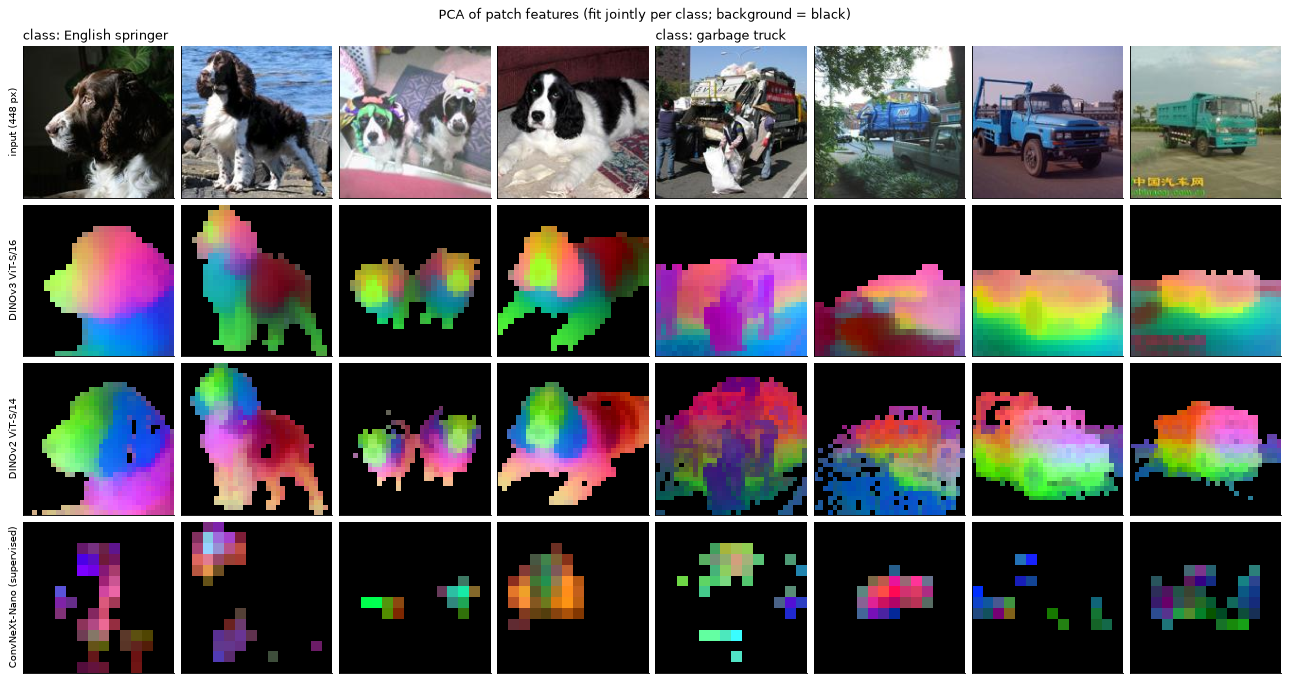

In [9]:
# --- PCA of patch tokens -> RGB for 4 images each of two classes ---
tf448 = rl.build_transform(train=False, size=448)
rng = np.random.default_rng(3)
val_targets = np.asarray(val_raw.targets)
CLASSES_VIS = [1, 6]  # English springer, garbage truck
vis_idx = [int(i) for c in CLASSES_VIS for i in rng.choice(np.flatnonzero(val_targets == c), 4, replace=False)]
x448 = torch.stack([tf448(val_raw[i][0]) for i in vis_idx]).to(device)  # (8, 3, 448, 448)
pca_maps = {}
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    for k, enc in encoders.items():
        _, patches = enc(x448)  # (8, h, w, D)
        patches = patches.cpu().numpy()
        # One joint PCA per class, so colours are comparable within each group of 4 images.
        pca_maps[k] = np.concatenate([rl.pca_rgb(patches[g * 4:(g + 1) * 4])[0] for g in range(2)])
rows = [("input (448 px)", [rl.denormalize(t) for t in x448])] + [(NAMES[k], list(pca_maps[k])) for k in encoders]
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.1 * len(rows)), dpi=80)
for r, (label, ims) in enumerate(rows):
    for c, im in enumerate(ims):
        axes[r, c].imshow(im, interpolation="nearest")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        axes[r, c].grid(False)
    axes[r, 0].set_ylabel(label, fontsize=9)
for g, c in enumerate(CLASSES_VIS):
    axes[0, 4 * g].set_title(f"class: {rl.CLASS_NAMES[c]}", loc="left")
fig.suptitle("PCA of patch features (fit jointly per class; background = black)")
viz.savefig(fig, PROJECT, "pca_patch_features")
plt.show()

A compact version of the same figure becomes the thumbnail for the repository README.

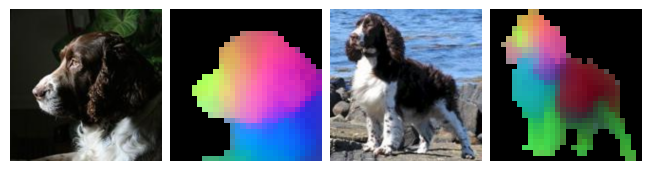

In [10]:
# --- Small thumbnail for the root README (two images + DINOv3 PCA maps, ~450 px wide) ---
fig, axes = plt.subplots(1, 4, figsize=(6.4, 1.7))
for j, i in enumerate([0, 1]):
    axes[2 * j].imshow(rl.denormalize(x448[i]))
    axes[2 * j + 1].imshow(pca_maps["dinov3_vits16"][i], interpolation="nearest")
for ax in axes:
    ax.axis("off")
viz.savefig(fig, PROJECT, "thumb", dpi=70)
plt.show()

## 8. Embedding plot (t-SNE)

t-SNE (van der Maaten & Hinton, 2008) maps high-dimensional points to 2-D while trying to preserve *neighbourhoods*. It matches
pairwise-similarity distributions with a heavy-tailed Student-t kernel in 2-D. Distances between clusters and cluster sizes in a t-SNE
plot carry little meaning. What matters is whether same-class points end up together. We embed the 3,925 L2-normalised validation CLS
features of each self-supervised encoder, with perplexity 30 and PCA initialisation.

In [11]:
# --- t-SNE of validation CLS features for the two self-supervised encoders ---
tsne = {}
for k in ["dinov3_vits16", "dinov2_vits14"]:
    X = F.normalize(feats[k]["val"]["cls"], dim=1).numpy()
    t0 = time.perf_counter()
    tsne[k] = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X)
    print(f"{NAMES[k]}: t-SNE on {X.shape} took {time.perf_counter() - t0:.1f} s")

DINOv3 ViT-S/16: t-SNE on (3925, 384) took 8.9 s


DINOv2 ViT-S/14: t-SNE on (3925, 384) took 4.7 s


## 9. Throughput and memory of the frozen encoders

Self-attention cost grows with the *square* of the token count, and doubling the resolution quadruples the number of patches.
We benchmark a batch of 64 at 224 and 448 px under fp16 autocast, after warm-up, with CUDA synchronisation.

In [12]:
# --- Benchmark forward passes at two resolutions (batch 64, fp16 autocast) ---
speed = {}
for k, enc in encoders.items():
    for res in [224, 448]:
        xb = torch.randn(64, 3, res, res, device=device)

        @torch.no_grad()
        def step(enc=enc, xb=xb):
            with torch.autocast("cuda", dtype=torch.float16):
                return enc(xb)

        for _ in range(5):
            step()
        reset_peak_vram()
        st = benchmark(step, warmup=3, iters=20)
        speed[(k, res)] = {"img/s": 64 * st["fps"], "ms / batch": st["mean_ms"], "peak VRAM [MiB]": peak_vram_mb()}
speed_df = pd.DataFrame(speed).T
speed_df.index = [f"{NAMES[k]} @ {r}px" for k, r in speed_df.index]
speed_df.style.format("{:.0f}")

,img/s,ms / batch,peak VRAM [MiB]
DINOv3 ViT-S/16 @ 224px,806,79,540
DINOv3 ViT-S/16 @ 448px,187,342,1119
DINOv2 ViT-S/14 @ 224px,895,72,573
DINOv2 ViT-S/14 @ 448px,195,329,1260
ConvNeXt-Nano (supervised) @ 224px,1072,60,809
ConvNeXt-Nano (supervised) @ 448px,255,251,2208


## Results

### Accuracy of frozen features

Left: validation accuracy of the three frozen-feature classifiers. Right: weighted k-NN accuracy as a function of $k$.

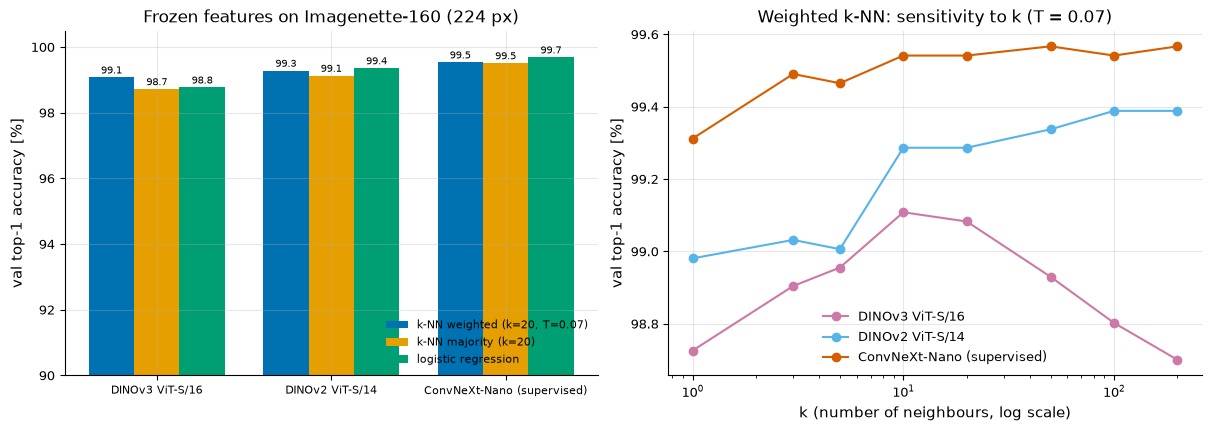

In [13]:
# --- Bar chart of k-NN / linear-probe accuracy + k-NN sweep over k ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
methods = ["k-NN weighted (k=20, T=0.07)", "k-NN majority (k=20)", "logistic regression"]
xs = np.arange(len(feats))
for m_i, m in enumerate(methods):
    vals = [100 * (linprobe[k]["val acc"] if m == "logistic regression" else knn[k][m]) for k in feats]
    bars = axes[0].bar(xs + (m_i - 1) * 0.26, vals, 0.26, color=viz.color(m_i, unit=True), label=m)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=7, padding=1)
axes[0].set_xticks(xs, [NAMES[k] for k in feats], fontsize=8)
axes[0].set(ylim=(90, 100.5), ylabel="val top-1 accuracy [%]", title="Frozen features on Imagenette-160 (224 px)")
axes[0].legend(loc="lower right", fontsize=8)
for i, k in enumerate(feats):
    axes[1].plot(KS, 100 * np.asarray(knn_sweep[k]), "o-", color=viz.color(i + 3, unit=True), label=NAMES[k])
axes[1].set_xscale("log")
axes[1].set(xlabel="k (number of neighbours, log scale)", ylabel="val top-1 accuracy [%]",
            title="Weighted k-NN: sensitivity to k (T = 0.07)")
axes[1].legend()
viz.savefig(fig, PROJECT, "frozen_features_accuracy")
plt.show()

### Few-shot curves

Mean accuracy over 5 random draws of the labelled subset, with shaded ±1 standard deviation. The x-axis is the number of labelled images per class,
on a log scale.

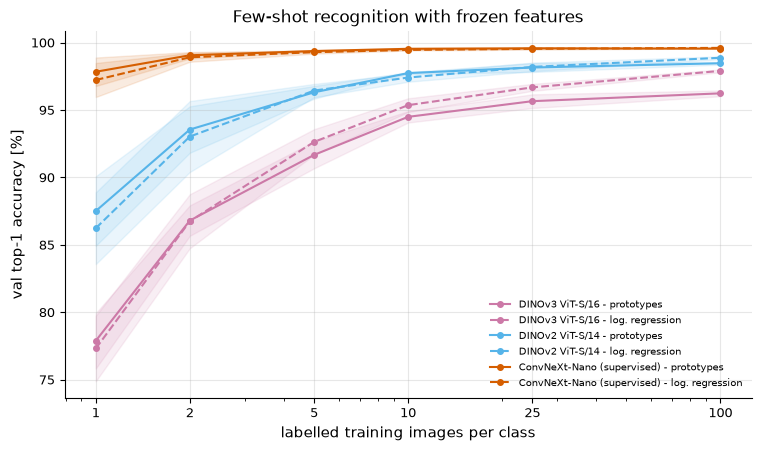

In [14]:
# --- Few-shot accuracy vs. labels per class ---
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for i, k in enumerate(feats):
    for m, ls in [("proto", "-"), ("logreg", "--")]:
        mu, sd = 100 * few[k][m].mean(1), 100 * few[k][m].std(1)
        ax.plot(SHOTS, mu, ls, marker="o", ms=4, color=viz.color(i + 3, unit=True),
                label=f"{NAMES[k]} - {'prototypes' if m == 'proto' else 'log. regression'}")
        ax.fill_between(SHOTS, mu - sd, mu + sd, color=viz.color(i + 3, unit=True), alpha=0.12)
ax.set_xscale("log")
ax.set_xticks(SHOTS, [str(s) for s in SHOTS])
ax.set(xlabel="labelled training images per class", ylabel="val top-1 accuracy [%]",
       title="Few-shot recognition with frozen features")
ax.legend(fontsize=7.5, loc="lower right")
viz.savefig(fig, PROJECT, "few_shot")
plt.show()

### Embedding plot

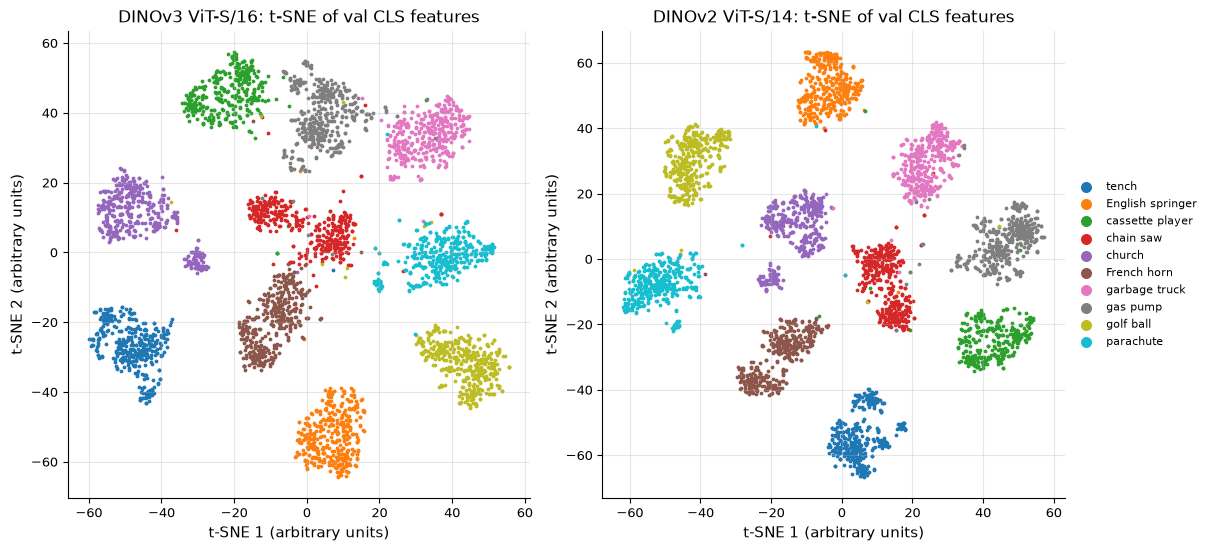

In [15]:
# --- Scatter the 2-D t-SNE embeddings coloured by class ---
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
for ax, k in zip(axes, tsne):
    for c in range(10):
        pts = tsne[k][y_va == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=3, color=cmap(c), label=rl.CLASS_NAMES[c])
    ax.set(title=f"{NAMES[k]}: t-SNE of val CLS features", xlabel="t-SNE 1 (arbitrary units)",
           ylabel="t-SNE 2 (arbitrary units)")
axes[1].legend(markerscale=4, fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
viz.savefig(fig, PROJECT, "tsne")
plt.show()

### Summary table

All numbers below were measured in this notebook on an RTX 5060 Laptop GPU (8 GB) with 224 px inputs unless noted. Few-shot values are means over 5 draws.

In [16]:
# --- Summary DataFrame ---
rows = []
for k in feats:
    rows.append({
        "encoder": NAMES[k],
        "k-NN weighted": knn[k]["k-NN weighted (k=20, T=0.07)"],
        "k-NN majority": knn[k]["k-NN majority (k=20)"],
        "logistic regression": linprobe[k]["val acc"],
        "1-shot prototypes": few[k]["proto"][SHOTS.index(1)].mean(),
        "5-shot prototypes": few[k]["proto"][SHOTS.index(5)].mean(),
        "10-shot log. reg.": few[k]["logreg"][SHOTS.index(10)].mean(),
        "img/s @224 (bs 64)": speed[(k, 224)]["img/s"],
        "img/s @448 (bs 64)": speed[(k, 448)]["img/s"],
        "VRAM @224 [MiB]": speed[(k, 224)]["peak VRAM [MiB]"],
        "VRAM @448 [MiB]": speed[(k, 448)]["peak VRAM [MiB]"],
    })
summary = pd.DataFrame(rows).set_index("encoder")
acc_cols = list(summary.columns[:6])
summary.style.format({c: "{:.2%}" for c in acc_cols} | {c: "{:.0f}" for c in summary.columns[6:]})

,k-NN weighted,k-NN majority,logistic regression,1-shot prototypes,5-shot prototypes,10-shot log. reg.,img/s @224 (bs 64),img/s @448 (bs 64),VRAM @224 [MiB],VRAM @448 [MiB]
encoder,,,,,,,,,,
DINOv3 ViT-S/16,99.08%,98.73%,98.78%,77.89%,91.67%,95.36%,806,187,540,1119
DINOv2 ViT-S/14,99.29%,99.13%,99.36%,87.51%,96.32%,97.41%,895,195,573,1260
ConvNeXt-Nano (supervised),99.54%,99.52%,99.69%,97.84%,99.38%,99.46%,1072,255,809,2208


### Takeaways

- **Frozen self-supervised features are strong without any fine-tuning.** At 224 px, weighted k-NN reaches 99.08 % (DINOv3
  ViT-S/16) and 99.29 % (DINOv2 ViT-S/14), and logistic regression on the frozen CLS token reaches 98.78 % and 99.36 %. Both beat every
  ResNet-18 and EfficientNet-B0 run of notebook 01 (at most 97.43 %), although those were trained at 160 px, so this is not a
  strict head-to-head.
- **On this dataset DINOv3 does not beat DINOv2 on global features.** DINOv3 is slightly behind on k-NN (99.08 % vs. 99.29 %) and
  logistic regression (98.78 % vs. 99.36 %) and clearly behind with few labels: 77.9 % vs. 87.5 % with one image per class
  (prototypes) and 91.7 % vs. 96.3 % with five. Its weighted k-NN accuracy peaks at k = 10 (99.11 %) and falls to 98.70 % at
  k = 200, while DINOv2's keeps improving up to k = 100 (99.39 %), so DINOv3's CLS neighbourhoods are less class-pure beyond the closest few images. We did not isolate the
  cause. Plausible factors are the upsampled 160 px images, the coarser patch grid (14x14 vs. 16x16 for DINOv2 at 224 px) and
  DINOv3's training emphasis on dense features. A newer model is not automatically better for *your* task, so measure.
- **For dense features the picture flips.** In the PCA maps, DINOv3's patch tokens form smooth, part-consistent regions: the dogs'
  heads, bodies and legs get matching colours across four different images. DINOv2's maps are speckled, with holes on the object
  and noisy background patches. On the garbage trucks both foreground masks also pick up some road and buildings. The supervised
  ConvNeXt's stride-32 grid (14x14 at 448 px) is too coarse, and its first principal component does not isolate the object. This
  comparison is qualitative (8 images).
- **The supervised CNN "wins" for the same reason as in notebook 01.** ConvNeXt-Nano features score highest everywhere (99.54 % k-NN,
  99.69 % logistic regression, 97.8 % with one label per class), but it was trained with labels for exactly these classes. The
  self-supervised encoders never saw a label, so their numbers are more indicative for objects no public model has seen.
- **fp16 is safe and the encoders are cheap.** fp16 autocast keeps the features at a cosine similarity of at least 0.99998 to fp32.
  At batch 64 and 224 px the encoders run at 806 (DINOv3), 895 (DINOv2) and 1072 (ConvNeXt) img/s in at most 809 MiB. At 448 px
  throughput drops 4.2-4.6x (4x more pixels) and peak memory stays at or below 2208 MiB. Extracting features for all 13,394 images
  took 20-21 s per encoder at 634-663 img/s, which was limited by JPEG decoding rather than by the GPU.

## Exercises

Solutions: `projects/02_representation_learning/solutions/02_self_supervised_features_solutions.py`.

**Exercise 1: CLS vs. CLS + mean patch.** The DINOv2 paper's linear evaluation concatenates the CLS token with the
average of the patch tokens. Using `feats[k]["train"]["mean_patch"]`, train the logistic regression on `[CLS, mean_patch]`
(each part L2-normalised) for both DINO models. Does it beat CLS alone?

In [17]:
# --- Exercise 1: linear probe on concatenated CLS + mean-patch features ---
# TODO: X = np.concatenate([normalize(cls), normalize(mean_patch)], axis=1) for train and val,
#       fit make_lr(C) with C chosen on a held-out split as in section 5, and compare.

**Exercise 2: dense correspondences (keypoint transfer).** Patch features are not only for classification. Take two
validation images of the same class at 448 px and compute DINOv3 patch tokens. For 6 foreground patches in image A, find the
most similar patch in image B (cosine similarity, `F.normalize` + matrix product), then draw lines between matching patch centres.
This is the core of *zero-shot keypoint transfer*, which lets a robot transfer a grasp point annotated on one mug to another mug.

In [18]:
# --- Exercise 2: nearest-neighbour patch matching between two images ---
# TODO: _, pa = encoders["dinov3_vits16"](xa); _, pb = encoders["dinov3_vits16"](xb)  # (1, 28, 28, 384)
#       sim = F.normalize(pa.flatten(1, 2), dim=-1) @ F.normalize(pb.flatten(1, 2), dim=-1).mT
#       pick query patches, take argmax over image-B patches, convert indices to pixel centres, plot.

**Exercise 3: image retrieval.** Use the DINOv3 CLS features as a search index. For three validation images, show the five
nearest *training* images by cosine similarity, along with their similarities and labels. Where does retrieval go wrong?

In [19]:
# --- Exercise 3: top-5 nearest training images for a few validation queries ---
# TODO: sims = F.normalize(feats[k]["val"]["cls"][q], dim=1) @ F.normalize(feats[k]["train"]["cls"], dim=1).T
#       top = sims.topk(5); load rl.make_dataset("train")[i] images and plot them in a grid.